# Diabetes Progression: Predictive Modeling Walkthrough

Compare Linear Regression, Decision Tree, and Random Forest models on scikit-learn's built-in diabetes dataset. The workflow is reproducible and does not download external data.

## 1. Load and inspect the data

The target is a quantitative disease-progression measure. The dataset is small and intended for learning, not clinical decision-making.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

from predictive_modeling.modeling import (
    FeatureEngineer,
    TARGET_NAME,
    build_models,
    load_dataset,
    run_experiment,
)

WORKING_DIR = Path.cwd()
OUTPUT_DIR = (
    WORKING_DIR if (WORKING_DIR / "pyproject.toml").exists() else WORKING_DIR.parent
)
features, target = load_dataset()
print(f'Features: {features.shape[0]} rows x {features.shape[1]} columns')
display(features.head())
display(target.rename(TARGET_NAME).describe().to_frame())
print('Missing values per feature:')
display(features.isna().sum().to_frame('missing_count').T)

Features: 442 rows x 10 columns


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,disease_progression
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


Missing values per feature:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
missing_count,0,0,0,0,0,0,0,0,0,0


## 2. Engineer features and prepare a holdout set

A BMI-by-age interaction gives the models a simple combined signal. Missing values are handled inside each training pipeline with median imputation, so imputation statistics are learned only from training data. Linear Regression additionally standardizes features.

In [2]:
engineered_preview = FeatureEngineer().fit_transform(features)
print('Engineered feature columns:')
display(engineered_preview.columns.to_frame(index=False, name='feature'))
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)
print(f'Train rows: {len(X_train)} | Holdout rows: {len(X_test)}')
print('Missing values in source data:', int(features.isna().sum().sum()))
print('Median imputation is applied in each fitted pipeline, including if future input data contains missing values.')

Engineered feature columns:


,feature
0,age
1,sex
2,bmi
3,bp
4,s1
5,s2
6,s3
7,s4
8,s5
9,s6


Train rows: 353 | Holdout rows: 89
Missing values in source data: 0
Median imputation is applied in each fitted pipeline, including if future input data contains missing values.


## 3. Train and compare regressors

All three models use the same split and evaluate MAE, RMSE, and R² on the untouched holdout observations. Lower MAE/RMSE is better; higher R² is better.

In [3]:
comparison_rows = []
for model_name, pipeline in build_models().items():
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    comparison_rows.append({
        'Model': model_name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions),
    })

comparison = pd.DataFrame(comparison_rows).sort_values('RMSE').reset_index(drop=True)
display(comparison.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R2': '{:.3f}'}))

,Model,MAE,RMSE,R2
0,Linear Regression,42.572,53.480,0.460
1,Random Forest,43.791,54.149,0.447
2,Decision Tree,44.519,55.617,0.416


## 4. Generate project artifacts

The shared experiment runner refits the workflows, selects the lowest-RMSE model, saves the model and report, and creates all visualizations under the repository root.

In [4]:
results = run_experiment(output_dir=OUTPUT_DIR)
display(pd.DataFrame(results['metrics']).T.sort_values('RMSE').style.format('{:.3f}'))
print('Selected model:', results['best_model'])
print('Saved report:', results['report_path'])
print('Saved model:', results['artifact_path'])

,MAE,RMSE,R2
Linear Regression,42.572,53.480,0.460
Random Forest,43.791,54.149,0.447
Decision Tree,44.519,55.617,0.416


Selected model: Linear Regression
Saved report: /workspaces/predictive-modeling-machine-learning/project_report.md
Saved model: /workspaces/predictive-modeling-machine-learning/models/best_model.pkl


## 5. Review generated visualizations

model_comparison.png


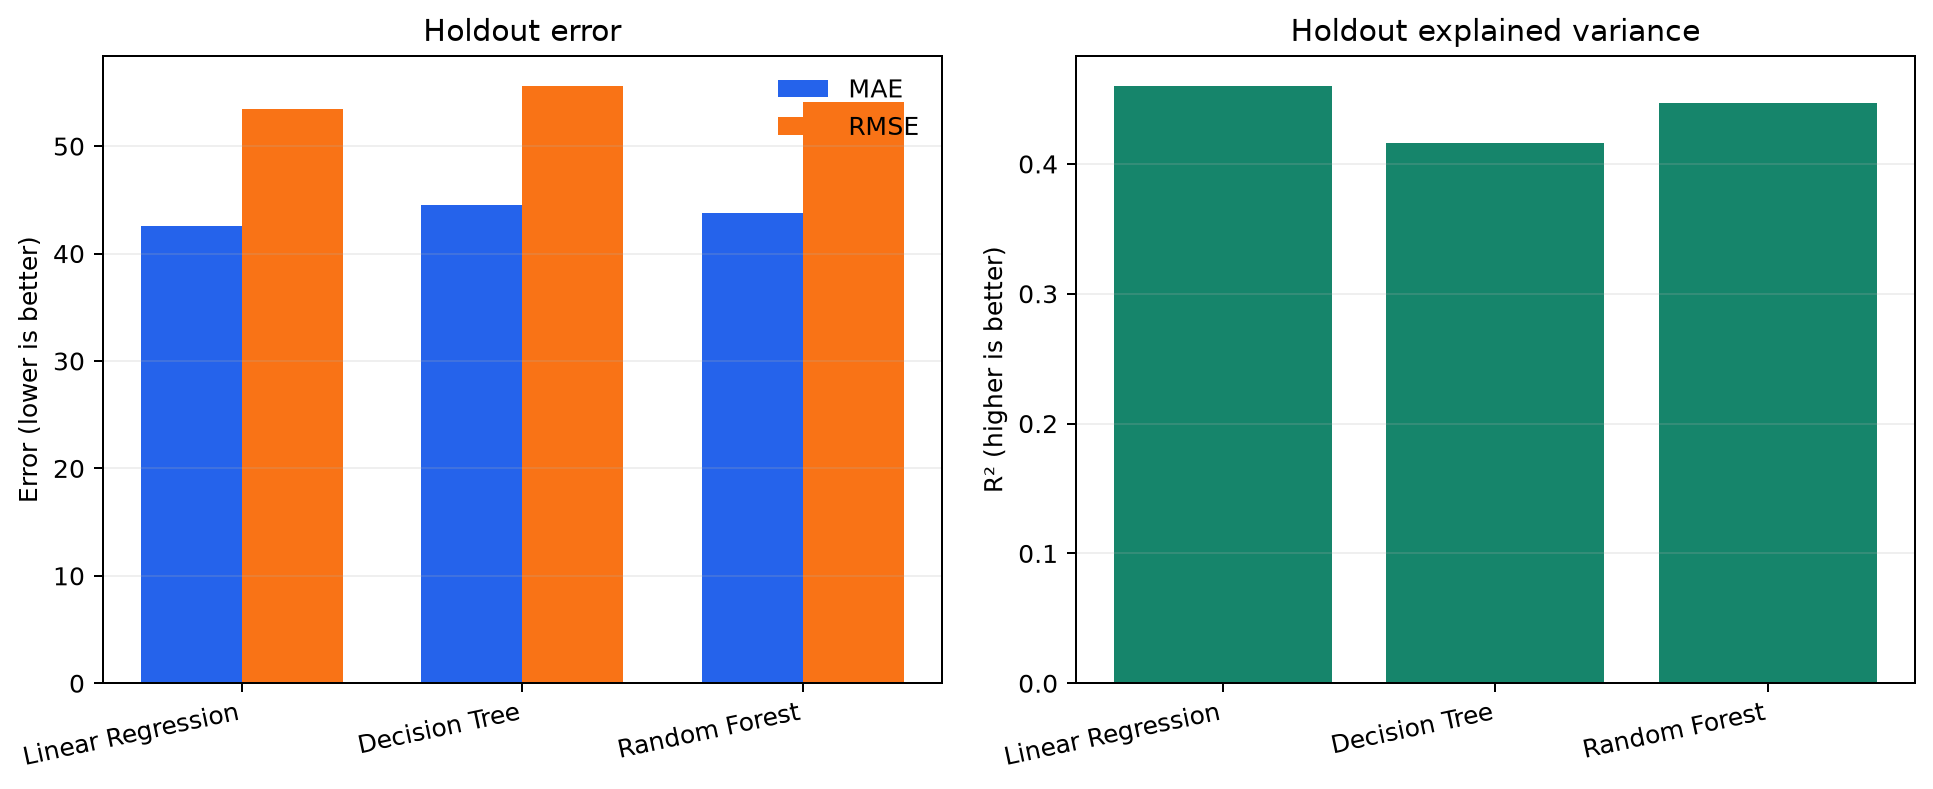

feature_importance.png


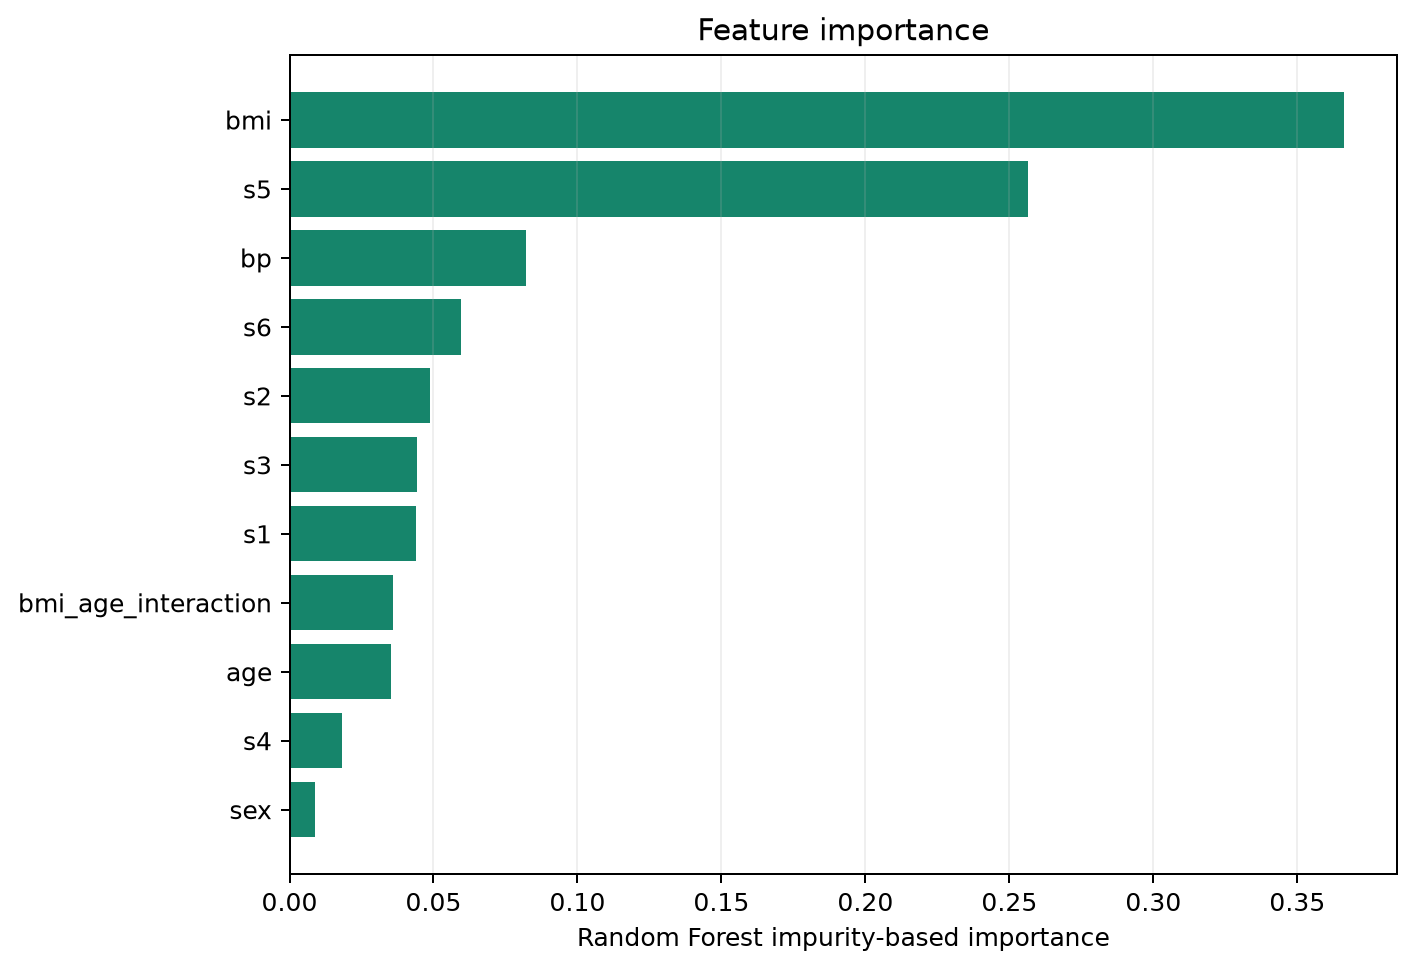

predictions.png


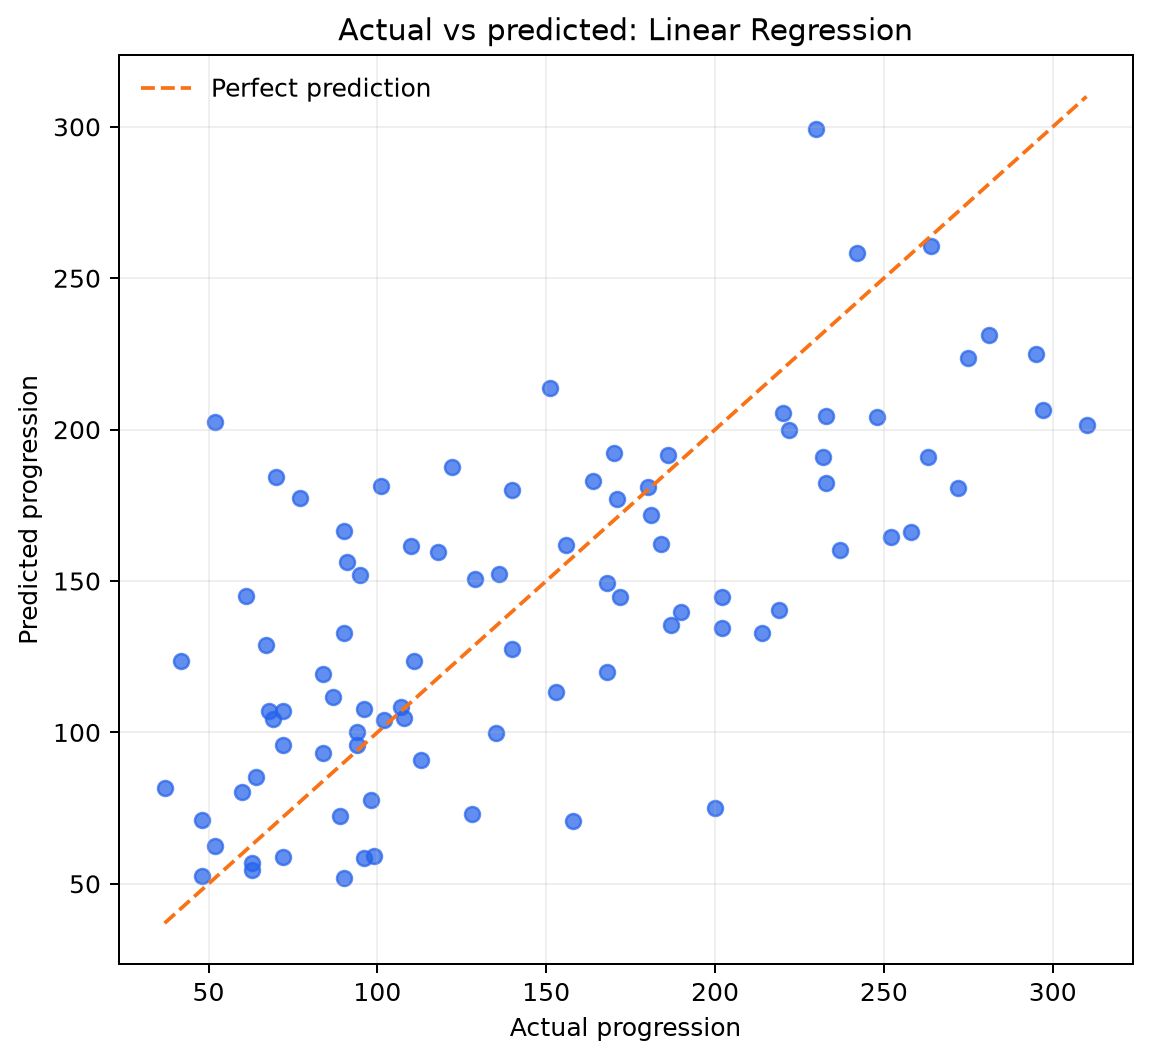

In [5]:
for chart_name in ('model_comparison.png', 'feature_importance.png', 'predictions.png'):
    chart_path = OUTPUT_DIR / 'images' / chart_name
    print(chart_name)
    display(Image(filename=str(chart_path)))

## 6. Load the selected model and predict

Pass a DataFrame with the original feature names and training column order to the saved pipeline.

In [6]:
artifact = joblib.load(OUTPUT_DIR / 'models' / 'best_model.pkl')
example_input = pd.DataFrame({column: [0.0] for column in artifact['feature_columns']})
example_prediction = artifact['model'].predict(example_input)[0]
print(f"{artifact['model_name']} predicted {TARGET_NAME}: {example_prediction:.1f}")

Linear Regression predicted disease_progression: 150.7


## Takeaways

Use the generated report for the full metric table and limitations. This single holdout comparison is a baseline; stronger evaluation would use cross-validation and an appropriate external validation set. Random Forest impurity importance describes model behavior and does not imply causal effects.